In [3]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random

1. Fix the number of membership functions
2. each position holds parameters for every MF type, an enable bit says which one out of the 13 is active

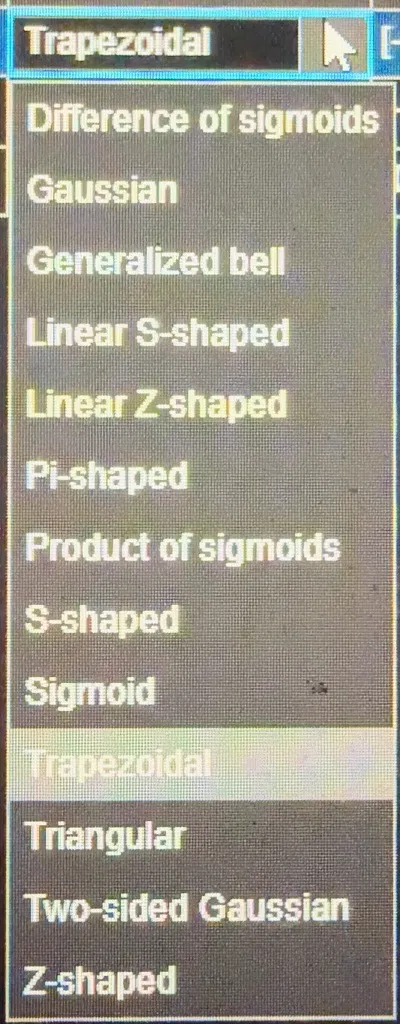

3. this means for MF with 3 MF's there should be 3 MF's within the MF
4. for the initial population randomization, there is a limit on min and max, but for subsequent populations they can freely move around the search space, there is some importance for getting a good range though, so Ill look at papers, my search space is slip ratio and derivative of slip ratio so our search space should be within well, sensible amounts of slip ratio

In [4]:
# Current Prototype Limited to Generating Slip Ratio MF's (Derivative Not Implemented Yet)
membership_function_amount = 3
# Slip Ratio Constants
slip_ratio_min = -0.25 # accelerating only so this should be pos but ill still account for full range
slip_ratio_max = 0.25
slip_ratio_optimal = 0.12
slip_ratio_derivative_min = None # calc from logs, check validity of calc with matt 
slip_ratio_derivative_max = None
# Inputs
slip_ratio_input = None
slip_ratio_derivative_input = None
# GA Encoding Constants
precision = 0.00196 # Need to figure out precision so will look at papers for that later
ub = slip_ratio_max
lb = slip_ratio_min
precision_bits = round(math.log2((ub - lb) / precision + 1))

In [8]:
"""
for each position, will have params for each 
aka after all mf types are encoded, last bits act like a mux to say which one we are using
generate membership function multiple times in generate genome

out_select = 0 is whole genome (returns just the genome)
out_select = 1 is Difference of Sigmoids, and its parameters (a1 c1 a2 c2) (returns a list, index 0 is all the bits for diff of sigmoids, index 1-4 are the parameters)
out_select = 2 is Gaussian, and its parameters (sigma c) (returns a list, index 0 is all the bits for gaussian, index 1-2 are the parameters)
out_select = 3 is Generalized Bell, and its parameters (a b c) (returns a list, index 0 is all the bits for generalized bell, index 1-3 are the parameters)
out_select = 4 is Linear S Shaped, and its parameters (a b) (returns a list, index 0 is all the bits for linear s shaped, index 1-2 are the parameters)
out_select = 5 is Linear Z Shaped, and its parameters (a b) (returns a list, index 0 is all the bits for linear z shaped, index 1-2 are the parameters)
out_select = 6 is Pi Shaped, and its parameters (a b c d) (returns a list, index 0 is all the bits for pi shaped, index 1-4 are the parameters)
out_select = 7 is Product of Sigmoids, and its parameters (a1 c1 a2 c2) (returns a list, index 0 is all the bits for product of sigmoids, index 1-4 are the parameters)
out_select = 8 is S Shaped, and its parameters (a b) (returns a list, index 0 is all the bits for s shaped, index 1-2 are the parameters)
out_select = 9 is Sigmoid, and its parameters (a c) (returns a list, index 0 is all the bits for sigmoid, index 1-2 are the parameters)
out_select = 10 is Trapezoidal, and its parameters (a b c d) (returns a list, index 0 is all the bits for trapezoidal, index 1-4 are the parameters)
out_select = 11 is Triangular, and its parameters (a b c) (returns a list, index 0 is all the bits for triangular, index 1-3 are the parameters)
out_select = 12 is Two Sided Gaussian, and its parameters (sigma1 c1 sigma2 c2) (returns a list, index 0 is all the bits for two sided gaussian, index 1-4 are the parameters)
out_select = 13 is Z Shaped, and its parameters (a b) (returns a list, index 0 is all the bits for z shaped, index 1-2 are the parameters)

"""

# helper function
def _param(bit_list, k):
    return bit_list[k*precision_bits:(k+1)*precision_bits]
    
def generate_genome():
    membership_function_string = [] # Create a list first, then later can make numpy arrays

    # Generate Difference of Sigmoids First (Pass List by Reference)
    def generate_diff_of_sigmoids(bit_list):
        # add a1 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c1 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add a2 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c2 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
            
    # methods to help debug if needed (difference of sigmoids)
    def extract_diff_of_sigmoids(bit_list):
        return bit_list[0:precision_bits*(3+1)]
    def extract_diff_of_sigmoids_a1(bit_list):
        return _param(bit_list, 0)
    def extract_diff_of_sigmoids_c1(bit_list):
        return _param(bit_list, 1)
    def extract_diff_of_sigmoids_a2(bit_list):
        return _param(bit_list, 2)
    def extract_diff_of_sigmoids_c2(bit_list):
        return _param(bit_list, 3)
        
    # test shit works (difference of sigmoids)
    generate_diff_of_sigmoids(membership_function_string)
    #print(membership_function_string)
    #print(extract_diff_of_sigmoids(membership_function_string))
    #print(extract_diff_of_sigmoids_a1(membership_function_string))
    #print(extract_diff_of_sigmoids_c1(membership_function_string))
    #print(extract_diff_of_sigmoids_a2(membership_function_string))
    #print(extract_diff_of_sigmoids_c2(membership_function_string))

    # Generate Gaussian (Pass List by Reference)
    def generate_gaussian(bit_list):
        # add sigma param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add center param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1

    # methods to help debug if needed (gaussian)
    def extract_gaussian(bit_list):
        return bit_list[precision_bits*4:precision_bits*(5+1)]
    def extract_gaussian_sigma(bit_list):
        return _param(bit_list, 4)
    def extract_gaussian_center(bit_list):
        return _param(bit_list, 5)

    # test shit works (gaussian)
    generate_gaussian(membership_function_string)
    #print(membership_function_string)
    #print(extract_gaussian(membership_function_string))
    #print(extract_gaussian_sigma(membership_function_string))
    #print(extract_gaussian_center(membership_function_string))

    # Generate Generalized Bell (Pass List by Reference)
    def generate_generalized_bell(bit_list):
        # add a param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add b param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1

    # methods to help debug if needed (generalized bell)
    def extract_generalized_bell(bit_list):
        return bit_list[precision_bits*6:precision_bits*(8+1)]
    def extract_generalized_bell_a(bit_list):
        return _param(bit_list, 6)
    def extract_generalized_bell_b(bit_list):
        return _param(bit_list, 7)
    def extract_generalized_bell_c(bit_list):
        return _param(bit_list, 8)

    # test shit works (generalized bell)
    generate_generalized_bell(membership_function_string)
    #print(membership_function_string)
    #print(extract_generalized_bell(membership_function_string))
    #print(extract_generalized_bell_a(membership_function_string))
    #print(extract_generalized_bell_b(membership_function_string))
    #print(extract_generalized_bell_c(membership_function_string))

    # Generate Linear S Shaped (Pass List by Reference)
    def generate_linear_s_shaped(bit_list):
        # add a param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add b param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1

    # methods to help debug if needed (linear s shaped)
    def extract_linear_s_shaped(bit_list):
        return bit_list[precision_bits*9:precision_bits*(10+1)]
    def extract_linear_s_shaped_a(bit_list):
        return _param(bit_list, 9)
    def extract_linear_s_shaped_b(bit_list):
        return _param(bit_list, 10)

    # test shit works (linear s shaped)
    generate_linear_s_shaped(membership_function_string)
    #print(membership_function_string)
    #print(extract_linear_s_shaped(membership_function_string))
    #print(extract_linear_s_shaped_a(membership_function_string))
    #print(extract_linear_s_shaped_b(membership_function_string))

    # Generate Linear Z Shaped (Pass List by Reference)
    def generate_linear_z_shaped(bit_list):
        # add a param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add b param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1

    # methods to help debug if needed (linear z shaped)
    def extract_linear_z_shaped(bit_list):
        return bit_list[precision_bits*11:precision_bits*(12+1)]
    def extract_linear_z_shaped_a(bit_list):
        return _param(bit_list, 11)
    def extract_linear_z_shaped_b(bit_list):
        return _param(bit_list, 12)

    # test shit works (linear z shaped)
    generate_linear_z_shaped(membership_function_string)
    #print(membership_function_string)
    #print(extract_linear_z_shaped(membership_function_string))
    #print(extract_linear_z_shaped_a(membership_function_string))
    #print(extract_linear_z_shaped_b(membership_function_string))

    # Generate Pi Shaped (Pass List by Reference)
    def generate_pi_shaped(bit_list):
        # add ab param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add b param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add d param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
            
    # methods to help debug if needed (difference of sigmoids)
    def extract_pi_shaped(bit_list):
        return bit_list[precision_bits*13:precision_bits*(16+1)]
    def extract_pi_shaped_a(bit_list):
        return _param(bit_list, 13)
    def extract_pi_shaped_b(bit_list):
        return _param(bit_list, 14)
    def extract_pi_shaped_c(bit_list):
        return _param(bit_list, 15)
    def extract_pi_shaped_d(bit_list):
        return _param(bit_list, 16)
        
    # test shit works (difference of sigmoids)
    generate_pi_shaped(membership_function_string)
    #print(membership_function_string)
    #print(extract_pi_shaped(membership_function_string))
    #print(extract_pi_shaped_a(membership_function_string))
    #print(extract_pi_shaped_b(membership_function_string))
    #print(extract_pi_shaped_c(membership_function_string))
    #print(extract_pi_shaped_d(membership_function_string))

    # Generate Product of Sigmoids (Pass List by Reference)
    def generate_product_of_sigmoids(bit_list):
        # add a1 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c1 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add a2 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c2 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
            
    # methods to help debug if needed (product of sigmoids)
    def extract_product_of_sigmoids(bit_list):
        return bit_list[precision_bits*17:precision_bits*(20+1)]
    def extract_product_of_sigmoids_a1(bit_list):
        return _param(bit_list, 17)
    def extract_product_of_sigmoids_c1(bit_list):
        return _param(bit_list, 18)
    def extract_product_of_sigmoids_a2(bit_list):
        return _param(bit_list, 19)
    def extract_product_of_sigmoids_c2(bit_list):
        return _param(bit_list, 20)
        
    # test shit works (product of sigmoids)
    generate_product_of_sigmoids(membership_function_string)
    #print(membership_function_string)
    #print(extract_product_of_sigmoids(membership_function_string))
    #print(extract_product_of_sigmoids_a1(membership_function_string))
    #print(extract_product_of_sigmoids_c1(membership_function_string))
    #print(extract_product_of_sigmoids_a2(membership_function_string))
    #print(extract_product_of_sigmoids_c2(membership_function_string))

    # Generate S Shaped (Pass List by Reference)
    def generate_s_shaped(bit_list):
        # add a param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add b param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1

    # methods to help debug if needed (s shaped)
    def extract_s_shaped(bit_list):
        return bit_list[precision_bits*21:precision_bits*(22+1)]
    def extract_s_shaped_a(bit_list):
        return _param(bit_list, 21)
    def extract_s_shaped_b(bit_list):
        return _param(bit_list, 22)

    # test shit works (s shaped)
    generate_s_shaped(membership_function_string)
    #print(membership_function_string)
    #print(extract_s_shaped(membership_function_string))
    #print(extract_s_shaped_a(membership_function_string))
    #print(extract_s_shaped_b(membership_function_string))

    # Generate Sigmoid (Pass List by Reference)
    def generate_sigmoid(bit_list):
        # add a param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1

    # methods to help debug if needed (sigmoid)
    def extract_sigmoid(bit_list):
        return bit_list[precision_bits*23:precision_bits*(24+1)]
    def extract_sigmoid_a(bit_list):
        return _param(bit_list, 23)
    def extract_sigmoid_c(bit_list):
        return _param(bit_list, 24)

    # test shit works (sigmoid)
    generate_sigmoid(membership_function_string)
    #print(membership_function_string)
    #print(extract_sigmoid(membership_function_string))
    #print(extract_sigmoid_a(membership_function_string))
    #print(extract_sigmoid_c(membership_function_string))

    # Generate Trapezoidal (Pass List by Reference)
    def generate_trapezoidal(bit_list):
        # add a param bits
        start = len(bit_list)   # bit index where trapezoidal begins
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add b param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add d param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
            
        # decode a b c d bits to integers (MSB first)
        n = precision_bits

        def _bits_to_int(offset):
            value = 0
            j = 0
            while j < n:
                value += bit_list[offset + j] * 2**(n - 1 - j)
                j += 1
            return value

        # Get the integer and binary values
        a_int = _bits_to_int(start)
        a_binary = _param(bit_list, 25)
        b_int = _bits_to_int(start + n)
        b_binary = _param(bit_list, 26)
        c_int = _bits_to_int(start + 2*n)
        c_binary = _param(bit_list, 27)
        d_int = _bits_to_int(start + 3*n)
        d_binary = _param(bit_list, 28)
        #print(a_int, b_int, c_int, d_int)

        # sort a-d by value, carrying each param's bits along
        pairs = sorted([(a_int, a_binary),
                        (b_int, b_binary),
                        (c_int, c_binary),
                        (d_int, d_binary)], key=lambda p: p[0])
        (a_int, a_binary), (b_int, b_binary), (c_int, c_binary), (d_int, d_binary) = pairs

        # write sorted bits back into the chromosome
        bit_list[start       : start + n  ] = a_binary
        bit_list[start + n   : start + 2*n] = b_binary
        bit_list[start + 2*n : start + 3*n] = c_binary
        bit_list[start + 3*n : start + 4*n] = d_binary
        
            
    # methods to help debug if needed (trapezoidal)
    def extract_trapezoidal(bit_list):
        return bit_list[precision_bits*25:precision_bits*(28+1)]
    def extract_trapezoidal_a(bit_list):
        return _param(bit_list, 25)
    def extract_trapezoidal_b(bit_list):
        return _param(bit_list, 26)
    def extract_trapezoidal_c(bit_list):
        return _param(bit_list, 27)
    def extract_trapezoidal_d(bit_list):
        return _param(bit_list, 28)
        
    # test shit works (trapezoidal)
    generate_trapezoidal(membership_function_string)
    #print(membership_function_string)
    #print(extract_trapezoidal(membership_function_string))
    #print(extract_trapezoidal_a(membership_function_string))
    #print(extract_trapezoidal_b(membership_function_string))
    #print(extract_trapezoidal_c(membership_function_string))
    #print(extract_trapezoidal_d(membership_function_string))

    # Generate Triangular (Pass List by Reference)
    def generate_triangular(bit_list):
        # add a param bits
        start = len(bit_list)   # bit index where trapezoidal begins
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add b param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
            
        # decode a b c bits to integers (MSB first)
        n = precision_bits

        def _bits_to_int(offset):
            value = 0
            j = 0
            while j < n:
                value += bit_list[offset + j] * 2**(n - 1 - j)
                j += 1
            return value

        # Get the integer and binary values
        a_int = _bits_to_int(start)
        a_binary = _param(bit_list, 29)
        b_int = _bits_to_int(start + n)
        b_binary = _param(bit_list, 30)
        c_int = _bits_to_int(start + 2*n)
        c_binary = _param(bit_list, 31)
        #print(a_int, b_int, c_int)

        # sort a-c by value, carrying each param's bits along
        pairs = sorted([(a_int, a_binary),
                        (b_int, b_binary),
                        (c_int, c_binary)], key=lambda p: p[0])
        (a_int, a_binary), (b_int, b_binary), (c_int, c_binary) = pairs

        # write sorted bits back into the chromosome
        bit_list[start       : start + n  ] = a_binary
        bit_list[start + n   : start + 2*n] = b_binary
        bit_list[start + 2*n : start + 3*n] = c_binary
        
            
    # methods to help debug if needed (triangular)
    def extract_triangular(bit_list):
        return bit_list[precision_bits*29:precision_bits*(31+1)]
    def extract_triangular_a(bit_list):
        return _param(bit_list, 29)
    def extract_triangular_b(bit_list):
        return _param(bit_list, 30)
    def extract_triangular_c(bit_list):
        return _param(bit_list, 31)
        
    # test shit works (triangular)
    generate_triangular(membership_function_string)
    #print(membership_function_string)
    #print(extract_triangular(membership_function_string))
    #print(extract_triangular_a(membership_function_string))
    #print(extract_triangular_b(membership_function_string))
    #print(extract_triangular_c(membership_function_string))

    # Generate two sided gaussian (Pass List by Reference)
    def generate_two_sided_gaussian(bit_list):
        # add sigma1 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c1 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add sigma2 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add c2 param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
            
    # methods to help debug if needed (two sidede gaussian)
    def extract_two_sided_gaussian(bit_list):
        return bit_list[precision_bits*32:precision_bits*(35+1)]
    def extract_two_sided_gaussian_sigma1(bit_list):
        return _param(bit_list, 32)
    def extract_two_sided_gaussian_c1(bit_list):
        return _param(bit_list, 33)
    def extract_two_sided_gaussian_sigma2(bit_list):
        return _param(bit_list, 34)
    def extract_two_sided_gaussian_c2(bit_list):
        return _param(bit_list, 35)
        
    # test shit works (two sided gaussian)
    generate_two_sided_gaussian(membership_function_string)
    #print(membership_function_string)
    #print(extract_two_sided_gaussian(membership_function_string))
    #print(extract_two_sided_gaussian_sigma1(membership_function_string))
    #print(extract_two_sided_gaussian_c1(membership_function_string))
    #print(extract_two_sided_gaussian_sigma2(membership_function_string))
    #print(extract_two_sided_gaussian_c2(membership_function_string))
          
    # Generate Z Shaped (Pass List by Reference)
    def generate_z_shaped(bit_list):
        # add a param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1
        # add b param bits
        i = 0
        while i < precision_bits:
            bit_list.append(round(random.random()))
            i += 1

    # methods to help debug if needed (s shaped)
    def extract_z_shaped(bit_list):
        return bit_list[precision_bits*36:precision_bits*(37+1)]
    def extract_z_shaped_a(bit_list):
        return _param(bit_list, 36)
    def extract_z_shaped_b(bit_list):
        return _param(bit_list, 37)

    # test shit works (s shaped)
    generate_z_shaped(membership_function_string)
    #print(membership_function_string)
    #print(extract_z_shaped(membership_function_string))
    #print(extract_z_shaped_a(membership_function_string))
    #print(extract_z_shaped_b(membership_function_string))

    # Generate Select Bits (13 diff funcs)
    def generate_select_bits(bit_list):
        select_int = random.randint(0, 12)
        select_bits = [int(b) for b in format(select_int, '04b')]
        bit_list.extend(select_bits)

    generate_select_bits(membership_function_string)
    #print(membership_function_string)
    assert len(membership_function_string) == 38*precision_bits + 4
    #print(len(membership_function_string))   # should print 308
    return membership_function_string
